Per lavorare con PyTorch non usiamo le liste ma i Tensori che sono a conti fatti simili alle liste 

In [1]:
%pip install torch

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch

In [3]:
import torch

# Due vettori (tensori a una dimensione) di 14 numeri interi
X = torch.tensor([55, 65, 75, 54, 67, 78, 53, 65, 76, 60, 70, 81, 51, 68], dtype=torch.float32).unsqueeze(1)  # .unsqueeze(1) aggiunge una dimensione in più per rappresentare il batch size
Y = torch.tensor([13, 18, 24, 12, 20, 26, 12, 18, 24, 14, 21, 28, 12, 20], dtype=torch.float32).unsqueeze(1)

print(X)
print(Y)


tensor([[55.],
        [65.],
        [75.],
        [54.],
        [67.],
        [78.],
        [53.],
        [65.],
        [76.],
        [60.],
        [70.],
        [81.],
        [51.],
        [68.]])
tensor([[13.],
        [18.],
        [24.],
        [12.],
        [20.],
        [26.],
        [12.],
        [18.],
        [24.],
        [14.],
        [21.],
        [28.],
        [12.],
        [20.]])


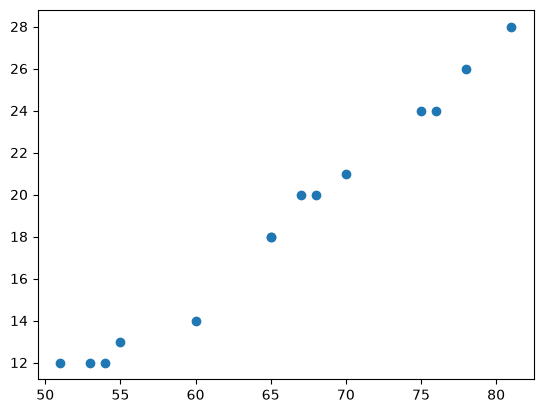

In [41]:
from matplotlib import pyplot

pyplot.scatter(X,Y)

In [42]:
# Definiamo un modello con un singolo neurone 
# Usiamo una banalissima funzione lineare y = wx + b, dove w è il peso e b è il bias.
# Quindi durante l'addestramento il modello imparerà a trovare i valori di w e b che meglio 
# approssimano la relazione tra x e y.
torch.manual_seed(42) # Impostiamo un seed per la riproducibilità dei risultati
# model = torch.nn.Linear(1, 1) # 1 input feature, 1 output feature che corrispondono alla temperatura in ingresso da convertire e alla temperatura in uscita convertita.

model = torch.nn.Sequential(
    torch.nn.Linear(1, 10), # 1 input feature, 10 output
    torch.nn.ReLU(),
    torch.nn.Linear(10, 10), # 10 input feature, 10 output
    torch.nn.ReLU(),
    torch.nn.Linear(10, 1), # 10 input feature, 1 output
)

#Ottimizzatore Adam per aggiornare i pesi del modello durante l'addestramento
optimizer = torch.optim.Adam(
    model.parameters(), 
    lr=0.01 #Learnin rate indica la velocità di addestramento per aggiornare i pesi del modello. Un valore troppo alto può portare a oscillazioni e instabilità, mentre un valore troppo basso può rallentare l'addestramento.
) 



loss_fn = torch.nn.MSELoss() # Devo decidere la loss function per il calcolo dell'errore e nel caso della regressione si usa l'errore quadratico medio
# Passiamo ora l'input 
model(X)

tensor([[-4.0739],
        [-4.8118],
        [-5.5498],
        [-4.0001],
        [-4.9594],
        [-5.7712],
        [-3.9263],
        [-4.8118],
        [-5.6236],
        [-4.4429],
        [-5.1808],
        [-5.9925],
        [-3.7787],
        [-5.0332]], grad_fn=<AddmmBackward0>)

Per il primo output bisognava prevedere 13 e ha previsto 42,8
Tutto ciò è normale visto che non abbiamo ancora addestato il modello

# Addestramento
Fornire ripetutamente al modello i dati di training in modo da comprendere i valori ottimali dei propri parametri
EPOCA: ogni ripetizione in cui forniamo al modello i dati di training nella loro interezza 

epoch: 0, loss: 591.55322265625
epoch: 100, loss: 6.896988391876221
epoch: 200, loss: 6.732985496520996
epoch: 300, loss: 6.526711940765381
epoch: 400, loss: 6.276348114013672
epoch: 500, loss: 5.982041358947754
epoch: 600, loss: 5.639365196228027
epoch: 700, loss: 5.238487720489502
epoch: 800, loss: 4.762392520904541
epoch: 900, loss: 4.185332298278809
epoch: 1000, loss: 3.4766829013824463
epoch: 1100, loss: 2.626281261444092
epoch: 1200, loss: 1.7140858173370361
epoch: 1300, loss: 0.9662989377975464
epoch: 1400, loss: 0.5783929228782654
epoch: 1500, loss: 0.4652906060218811
epoch: 1600, loss: 0.4461285471916199
epoch: 1700, loss: 0.44396716356277466
epoch: 1800, loss: 0.44378548860549927
epoch: 1900, loss: 0.4437715709209442
epoch: 2000, loss: 0.443771630525589
epoch: 2100, loss: 0.443771094083786
epoch: 2200, loss: 0.44377127289772034
epoch: 2300, loss: 0.4437714219093323
epoch: 2400, loss: 0.4437718093395233
epoch: 2500, loss: 0.44377079606056213
epoch: 2600, loss: 0.44377169013023

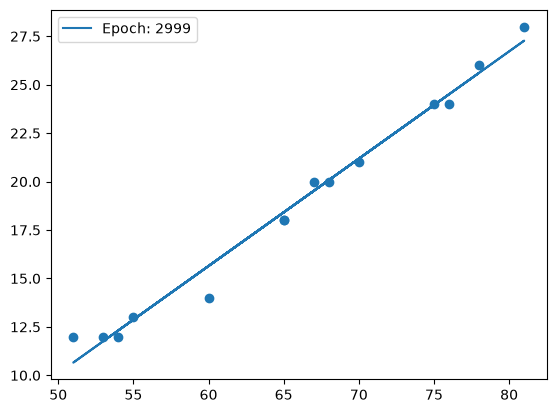

In [43]:
for epoch in range(3000):
    optimizer.zero_grad() # Resettiamo i gradienti per il prossimo passo di ottimizzazione
    y_pred = model(X)
    loss = loss_fn(y_pred, Y) # Calcolo l'errore usando i dati reali rispetto a quelli previsti
    loss.backward() # Calcoliamo il gradiente della loss function rispetto ai pesi del modello
    optimizer.step() # Aggiorniamo i pesi del modello 
      
    if epoch % 100 == 0:
        print(f"epoch: {epoch}, loss: {loss}")
    if epoch in [2999]:
        pyplot.plot(X, y_pred.detach(), label=f"Epoch: {epoch}")

pyplot.scatter(X,Y)
pyplot.legend()

In [44]:
current_temperature = torch.tensor([70], dtype=torch.float32)
model(current_temperature)

tensor([21.1617], grad_fn=<ViewBackward0>)